# ForecastIQ — Unified matched forecasting benchmark

This notebook constructs a matched Scenario-A leaderboard for all available models on the fixed 400-series panel and `d_1886–d_1913`. It reports unavailable or misaligned models explicitly. Scenario B is kept separate and is not ranked with Scenario A. The final period is an **explored benchmark**; multi-origin results are required for stronger claims.

In [1]:
from pathlib import Path
import sys,numpy as np,pandas as pd,matplotlib.pyplot as plt
PROJECT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
if str(PROJECT) not in sys.path:sys.path.insert(0,str(PROJECT))
from src.evaluation.evaluation_panel import validate_panel,prediction_records
from src.evaluation.benchmark import tune_statistical_panel,leaderboard_from_records,multi_origin_statistical
from src.evaluation.comparison import assert_matched_predictions
from src.evaluation.uncertainty import paired_model_comparison,paired_hierarchical_comparison
from src.evaluation.nested_selection import assert_nested_history
from src.evaluation.multi_origin import (assert_complete_matched_backtest,coverage_table,
    diagnostic_breakdowns,multi_origin_lightgbm)
from src.experiments.config import ExperimentConfig,save_manifest
OUT=PROJECT/'data'/'processed';CONFIG=ExperimentConfig()
panel=pd.read_parquet(OUT/'evaluation_panel.parquet');validate_panel(panel);ids=set(panel.series_id)
status=[]

## Statistical models — identical panel, validation-only alpha selection

In [2]:
stat_records,stat_validation,stat_selection=tune_statistical_panel(panel,validation_origins=CONFIG.validation_origins,
    final_origin=CONFIG.test_origin,horizon=CONFIG.horizon,alphas=CONFIG.alphas,experiment_id='unified-explored-final')
stat_validation.to_csv(OUT/'unified_statistical_validation.csv',index=False)
stat_selection.to_csv(OUT/'unified_statistical_selection.csv',index=False)
status.extend({'model':m,'scenario':'seen','status':'available'} for m in sorted(stat_records.model.unique()))

## Normalize existing ML and corrected DL predictions

In [3]:
def normalize_ml(path,source_model,target_model):
    raw=pd.read_csv(path);raw=raw[raw.model==source_model].copy()
    if set(raw.series_id)!=ids:raise ValueError(f'{target_model} series do not match evaluation panel')
    raw=raw.merge(panel[['series_id','item_id','store_id','demand_type']],on=['series_id','demand_type'],validate='many_to_one')
    raw['experiment_id']='unified-explored-final';raw['scenario']='seen';raw['model']=target_model
    raw['forecast_origin']='d_1885';raw['target_day']='d_'+(1885+raw.horizon.astype(int)).astype(str);raw['horizon_step']=raw.horizon.astype(int)
    return raw[['experiment_id','scenario','model','series_id','item_id','store_id','demand_type','forecast_origin','target_day','horizon_step','actual','prediction']]

records=[stat_records]
sources=[(OUT/'phase3a_all_test_forecasts.csv','LightGBM_B_calendar','Direct LightGBM'),
         (OUT/'phase3b_all_test_forecasts.csv','Hurdle_LightGBM','Hurdle LightGBM')]
for path,source,target in sources:
    try:records.append(normalize_ml(path,source,target));status.append({'model':target,'scenario':'seen','status':'available'})
    except Exception as error:status.append({'model':target,'scenario':'seen','status':f'failed: {error}'})
dl_path=OUT/'phase3d_standardized_predictions.csv'
if dl_path.exists():
    dl=pd.read_csv(dl_path)
    for model in ['NHITS','DeepAR']:
        part=dl[dl.model==model]
        if set(part.series_id)==ids:records.append(part[stat_records.columns]);status.append({'model':model,'scenario':'seen','status':'available'})
        else:status.append({'model':model,'scenario':'seen','status':'failed: panel mismatch'})
else:
    status.extend([{'model':'NHITS','scenario':'seen','status':'not run: execute corrected Notebook 3D'},
                   {'model':'DeepAR','scenario':'seen','status':'not run: execute corrected Notebook 3D'}])
status=pd.DataFrame(status);display(status)

,model,scenario,status
0,Average,seen,available
1,Croston,seen,available
2,Naive,seen,available
3,SBA,seen,available
4,SES,seen,available
5,SeasonalNaive,seen,available
6,TSB,seen,available
7,Direct LightGBM,seen,available
8,Hurdle LightGBM,seen,available
9,NHITS,seen,available


## Strict matched leaderboard, diagnostics, and paired uncertainty

,model,series,MAE,MASE,valid_MASE,RMSSE,valid_RMSSE,WAPE_pct,bias,total_cost_proxy
3,Direct LightGBM,400.0,2.0392,1.5581,400.0,0.8851,400.0,63.6534,0.1967,64110.0410
4,Hurdle LightGBM,400.0,2.0454,1.5598,400.0,0.8859,400.0,63.8462,0.2415,63314.5446
8,SES,400.0,2.0698,1.5719,400.0,0.9117,400.0,64.6084,0.1189,66880.4428
10,TSB,400.0,2.0742,1.5696,400.0,0.9110,400.0,64.7451,0.1243,66906.2005
7,SBA,400.0,2.2018,1.6147,400.0,0.9354,400.0,68.7281,0.0878,72011.2303
1,Croston,400.0,2.2671,1.6502,400.0,0.9429,400.0,70.7686,0.3700,67887.5019
0,Average,400.0,2.4428,1.6904,400.0,1.0122,400.0,76.2532,-0.1565,85583.5523
9,SeasonalNaive,400.0,2.5064,1.8094,400.0,1.1603,400.0,78.2386,-0.0104,84448.0000
6,Naive,400.0,2.6848,1.9377,400.0,1.1470,400.0,83.8071,0.4614,79874.0000
2,DeepAR,400.0,3.0004,2.2473,400.0,1.2019,400.0,93.6578,-2.4034,154650.2681


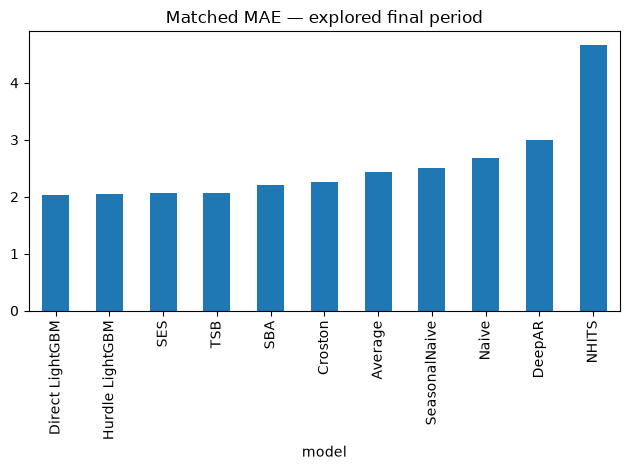

model,Average,Croston,DeepAR,Direct LightGBM,Hurdle LightGBM,NHITS,Naive,SBA,SES,SeasonalNaive,TSB
demand_type,,,,,,,,,,,
Erratic,4.260,3.910,4.579,3.545,3.562,6.881,4.586,3.793,3.562,4.233,3.595
Intermittent,0.741,0.872,0.840,0.678,0.680,2.722,0.747,0.834,0.673,0.764,0.671
Lumpy,1.602,1.559,1.742,1.493,1.508,3.346,1.892,1.496,1.533,1.802,1.538
Smooth,3.168,2.728,4.840,2.441,2.432,5.734,3.515,2.684,2.510,3.226,2.492


,clusters,mean_difference,median_difference,percent_improved,ci_lower,ci_upper,model_a,model_b,delta_definition
0,351,0.039738,0.006630,45.014245,-0.024235,0.097153,TSB,Direct LightGBM,MAE(TSB) - MAE(Direct LightGBM)
1,351,0.037604,0.005001,47.293447,-0.027934,0.101553,TSB,Hurdle LightGBM,MAE(TSB) - MAE(Hurdle LightGBM)
2,351,-0.002133,0.001944,46.723647,-0.023684,0.018786,Direct LightGBM,Hurdle LightGBM,MAE(Direct LightGBM) - MAE(Hurdle LightGBM)
3,351,-2.645277,-0.752225,78.632479,-3.162675,-2.155865,Direct LightGBM,NHITS,MAE(Direct LightGBM) - MAE(NHITS)
4,351,-0.940355,-0.226593,76.353276,-1.226889,-0.676354,Direct LightGBM,DeepAR,MAE(Direct LightGBM) - MAE(DeepAR)
5,351,1.704922,0.249471,35.897436,1.251056,2.203730,NHITS,DeepAR,MAE(NHITS) - MAE(DeepAR)


Scenario B is not ranked here: no standardized unseen-series predictions are currently available.


In [4]:
available=pd.concat(records,ignore_index=True);assert_matched_predictions(available)
leaderboard,series_metrics=leaderboard_from_records(available,panel)
leaderboard.to_csv(OUT/'unified_explored_final_leaderboard.csv',index=False);available.to_csv(OUT/'unified_standardized_predictions.csv',index=False)
display(leaderboard.round(4));leaderboard.plot.bar(x='model',y='MAE',legend=False,title='Matched MAE — explored final period');plt.tight_layout();plt.show()
breakdowns=diagnostic_breakdowns(available,panel)
for name,table in breakdowns.items():
    table.to_csv(OUT/f'unified_explored_breakdown_{name}.csv',index=False)
display(breakdowns['demand_type'].pivot(index='demand_type',columns='model',values='MAE').round(3))
pairs=[('TSB','Direct LightGBM'),('TSB','Hurdle LightGBM'),('Direct LightGBM','Hurdle LightGBM'),
       ('Direct LightGBM','NHITS'),('Direct LightGBM','DeepAR'),('NHITS','DeepAR')]
comparisons=[]
for a,b in pairs:
    if {a,b}.issubset(set(available.model)):
        comparisons.append(paired_model_comparison(available,a,b,cluster='item_id'))
pd.DataFrame(comparisons).to_csv(OUT/'unified_paired_comparisons.csv',index=False);display(pd.DataFrame(comparisons))
print('Scenario B is not ranked here: no standardized unseen-series predictions are currently available.')

## Multi-origin protocol

The predeclared non-overlapping origins are read from `ExperimentConfig.backtest_origins`. Statistical models run immediately. Set `RUN_ML_MULTI_ORIGIN=True` for the feasible LightGBM refits. DL records are loaded only from Notebook 3D's explicit research run. Coverage is checked for every model/origin; incomplete work remains visible and is excluded from the complete leaderboard.

,model,forecast_origin,rows,unique_rows,expected_rows,status
0,Average,1717,11200,11200,11200,complete
1,Average,1745,11200,11200,11200,complete
2,Average,1773,11200,11200,11200,complete
3,Average,1801,11200,11200,11200,complete
4,Average,1829,11200,11200,11200,complete
...,...,...,...,...,...,...
61,DeepAR,1745,11200,11200,11200,complete
62,DeepAR,1773,11200,11200,11200,complete
63,DeepAR,1801,11200,11200,11200,complete
64,DeepAR,1829,11200,11200,11200,complete


forecast_origin,d_1717,d_1745,d_1773,d_1801,d_1829,d_1857
model,,,,,,
Average,2.412,2.474,2.638,2.452,2.477,2.445
Croston,2.341,2.340,2.400,2.314,2.320,2.287
DeepAR,3.252,3.057,3.190,3.384,3.282,3.368
Direct LightGBM,2.145,2.038,2.003,2.099,2.141,2.148
Hurdle LightGBM,2.151,2.010,1.996,2.092,2.156,2.140
NHITS,3.756,3.537,3.646,3.802,3.913,3.953
Naive,2.698,2.717,2.789,2.887,2.834,2.752
SBA,2.269,2.212,2.316,2.266,2.255,2.202
SES,2.186,1.938,2.059,2.183,2.163,2.074


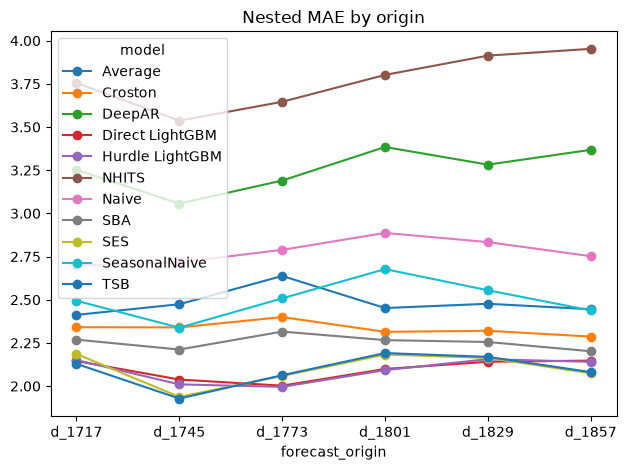

,model_a,model_b,mean_difference,median_difference,percent_first_model_wins,ci_lower,ci_upper,matched_series,matched_products,matched_origins,matched_observations,bootstrap,seed,supports_nonzero_difference
0,TSB,Direct LightGBM,-0.002021,0.007029,47.708333,-0.079542,0.062074,400,351,6,67200,origins then product clusters,42,False
1,TSB,Hurdle LightGBM,0.002681,0.007045,47.291667,-0.069419,0.066530,400,351,6,67200,origins then product clusters,42,False
2,Direct LightGBM,Hurdle LightGBM,0.004702,0.002155,48.041667,-0.012432,0.021993,400,351,6,67200,origins then product clusters,42,False
3,Direct LightGBM,NHITS,-1.672135,-0.583368,73.958333,-1.835651,-1.509730,400,351,6,67200,origins then product clusters,42,True
4,Direct LightGBM,DeepAR,-1.160010,-0.648689,81.208333,-1.267364,-1.043831,400,351,6,67200,origins then product clusters,42,True
5,NHITS,DeepAR,0.512126,0.028667,46.416667,0.401952,0.628625,400,351,6,67200,origins then product clusters,42,True


Complete models: ['Average', 'Croston', 'DeepAR', 'Direct LightGBM', 'Hurdle LightGBM', 'NHITS', 'Naive', 'SBA', 'SES', 'SeasonalNaive', 'TSB']
Incomplete models are shown in coverage and excluded, never silently mixed.


In [5]:
RUN_ML_MULTI_ORIGIN=True
multi_records,multi_validation,stat_nested_selection=multi_origin_statistical(panel,CONFIG.backtest_origins,horizon=CONFIG.horizon,
    alphas=CONFIG.alphas,experiment_id='statistical-multi-origin',return_selection=True)
multi_records.to_csv(OUT/'unified_statistical_multi_origin_predictions.csv',index=False)
multi_validation.to_csv(OUT/'unified_statistical_multi_origin_validation.csv',index=False)
stat_nested_selection.to_csv(OUT/'unified_statistical_nested_selection.csv',index=False)
stat_boundaries=(multi_validation[['evaluation_origin','inner_validation_origins']].drop_duplicates('evaluation_origin')
                 .explode('inner_validation_origins').rename(columns={'evaluation_origin':'outer_origin','inner_validation_origins':'inner_origin'}))
assert_nested_history(stat_boundaries,horizon=CONFIG.horizon)
if RUN_ML_MULTI_ORIGIN:
    ml_multi,ml_history=multi_origin_lightgbm(panel,CONFIG.backtest_origins,horizon=CONFIG.horizon,
                                   experiment_id='lightgbm-multi-origin',return_history=True)
    ml_multi.to_csv(OUT/'unified_ml_multi_origin_predictions.csv',index=False)
    ml_history.to_csv(OUT/'unified_ml_selection_history.csv',index=False)
ml_path=OUT/'unified_ml_multi_origin_predictions.csv'
dl_multi_path=OUT/'phase3d_multi_origin_predictions.csv'
multi_parts=[multi_records]
if ml_path.exists():multi_parts.append(pd.read_csv(ml_path))
if dl_multi_path.exists():multi_parts.append(pd.read_csv(dl_multi_path))
multi_available=pd.concat(multi_parts,ignore_index=True)
all_models=['Average','Naive','SeasonalNaive','SES','Croston','SBA','TSB',
            'Direct LightGBM','Hurdle LightGBM','NHITS','DeepAR']
coverage=coverage_table(multi_available,all_models,CONFIG.backtest_origins,
                        series_count=len(panel),horizon=CONFIG.horizon)
coverage.to_csv(OUT/'unified_multi_origin_coverage.csv',index=False);display(coverage)
complete_models=coverage.groupby('model').status.apply(lambda s:(s=='complete').all())
complete_models=complete_models[complete_models].index.tolist()
complete=multi_available[multi_available.model.isin(complete_models)].copy()
if complete_models:
    assert_complete_matched_backtest(complete,complete_models,CONFIG.backtest_origins,
                                     series_count=len(panel),horizon=CONFIG.horizon)
multi_summary=(complete.assign(abs_error=lambda x:(x.prediction-x.actual).abs())
               .groupby(['model','forecast_origin'],as_index=False).abs_error.mean())
display(multi_summary.pivot(index='model',columns='forecast_origin',values='abs_error').round(3))
if len(complete):
    nested_breakdowns=diagnostic_breakdowns(complete,panel)
    for name,table in nested_breakdowns.items():table.to_csv(OUT/f'unified_nested_breakdown_{name}.csv',index=False)
    multi_summary.pivot(index='forecast_origin',columns='model',values='abs_error').plot(marker='o',title='Nested MAE by origin')
    plt.tight_layout();plt.show()
multi_pairs=[]
for a,b in pairs:
    if {a,b}.issubset(complete_models):
        multi_pairs.append(paired_hierarchical_comparison(complete,a,b,n_bootstrap=2000,seed=42))
pd.DataFrame(multi_pairs).to_csv(OUT/'unified_multi_origin_paired_comparisons.csv',index=False)
display(pd.DataFrame(multi_pairs))
print('Complete models:',complete_models)
print('Incomplete models are shown in coverage and excluded, never silently mixed.')

In [6]:
manifest=save_manifest(PROJECT/'results'/'manifests'/'unified_benchmark.json','unified-benchmark',CONFIG,
    sources=[OUT/'evaluation_panel.parquet'],extra={'available_models':sorted(available.model.unique()),
    'failed_or_missing':status[status.status!='available'].to_dict('records'),'final_period_status':'previously explored',
    'multi_origin_complete_models':complete_models,'multi_origin_coverage':coverage.to_dict('records')})
print('Manifest:',manifest['experiment_id'])

Manifest: unified-benchmark-20261101T131433Z
